# 信息瓶颈（Information Bottleneck）演示：aIB 与 sIB

本笔记本演示两种经典的硬聚类信息瓶颈算法：
1. **凝聚式信息瓶颈（aIB）**：自底向上贪心合并，每一步选择使互信息损失 $\Delta I(t_i, t_j) = (p(t_i)+p(t_j))\,\mathrm{JSD}_{\pi_i,\pi_j}(p(y|t_i), p(y|t_j))$ 最小的一对簇合并。
2. **序列信息瓶颈（sIB）**：先随机初始化确定性划分，再依次将样本 $x$ 从当前簇抽出并重新分配到使 $I(T;Y)$ 最大（等价于合并代价最小）的簇，直至收敛。

数据设定：$X \in \{1, \dots, 100\}$ 随机分为 10 簇，$Y$ 为 25 维特征向量；每簇对应随机 8 个特征，生成概率为 $0.5$，其余 17 个特征生成概率为 $0.1$。

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from data import generate_data, compute_joint_distribution, compute_cluster_distribution
from evaluator import mutual_information, evaluate_clustering, _contingency_matrix
from solver import agglomerative_ib, sequential_ib

plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']

## 1. 生成数据与概率分布

In [9]:
data = generate_data(
    n_x=100,
    n_clusters=10,
    n_features=25,
    n_cluster_features=8,
    p_in=0.5,
    p_out=0.1,
    n_draws=100,
    seed=42,
)

X = data['X']
true_clusters = data['true_clusters']
cluster_features = data['cluster_features']
counts = data['counts']

p_xy, p_x, p_y, p_y_given_x = compute_joint_distribution(counts)
i_xy = mutual_information(p_xy)

print(f'样本数 |X| = {len(X)}, 特征数 |Y| = {p_y_given_x.shape[1]}, 真实簇数 K = {cluster_features.shape[0]}')
print(f'真实簇大小分布: {np.bincount(true_clusters)}')
print(f'原始互信息 I(X; Y) = {i_xy:.4f} bits')

样本数 |X| = 100, 特征数 |Y| = 25, 真实簇数 K = 10
真实簇大小分布: [ 9  9  6  9 15  7 11 15 12  7]
原始互信息 I(X; Y) = 0.4259 bits


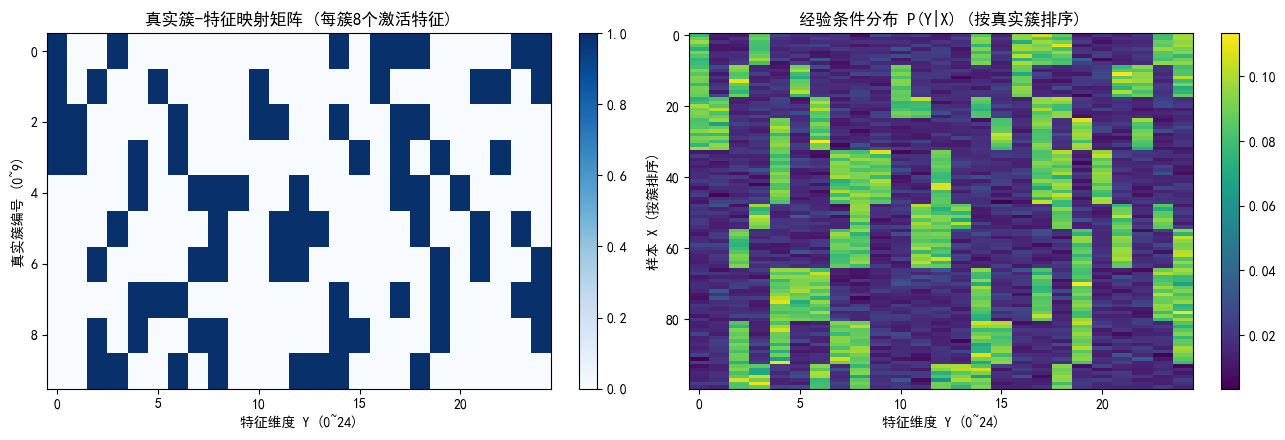

In [13]:
order = np.argsort(true_clusters)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

im0 = axes[0].imshow(cluster_features.astype(float), aspect='auto', cmap='Blues')
axes[0].set_title('真实簇-特征映射矩阵 (每簇8个激活特征)')
axes[0].set_xlabel('特征维度 Y (0~24)')
axes[0].set_ylabel('真实簇编号 (0~9)')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(p_y_given_x[order], aspect='auto', cmap='viridis')
axes[1].set_title('经验条件分布 P(Y|X) (按真实簇排序)')
axes[1].set_xlabel('特征维度 Y (0~24)')
axes[1].set_ylabel('样本 X (按簇排序)')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

## 2. 凝聚式信息瓶颈（aIB）

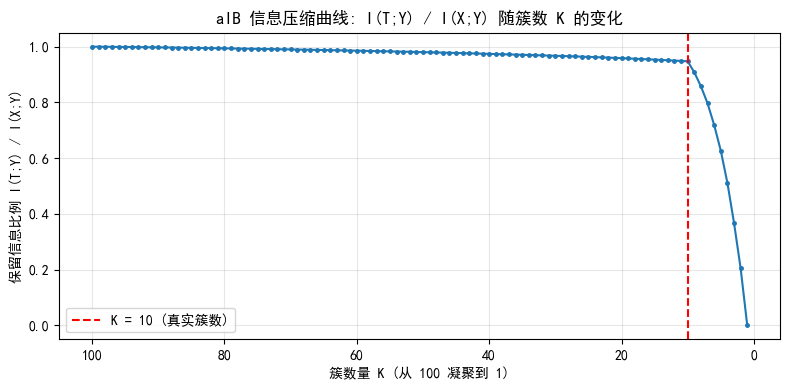

In [10]:
aib_res = agglomerative_ib(p_x, p_y_given_x, n_clusters=10, record_full_hierarchy=True)
hist = aib_res['history']
ks = [h['k'] for h in hist]
i_tys = [h['I(T;Y)'] for h in hist]
ratios = [val / i_xy for val in i_tys]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, ratios, marker='o', markersize=2.5, linewidth=1.5)
ax.axvline(10, color='red', linestyle='--', label='K = 10 (真实簇数)')
ax.invert_xaxis()
ax.set_title('aIB 信息压缩曲线: I(T;Y) / I(X;Y) 随簇数 K 的变化')
ax.set_xlabel('簇数量 K (从 100 凝聚到 1)')
ax.set_ylabel('保留信息比例 I(T;Y) / I(X;Y)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. 序列信息瓶颈（sIB）

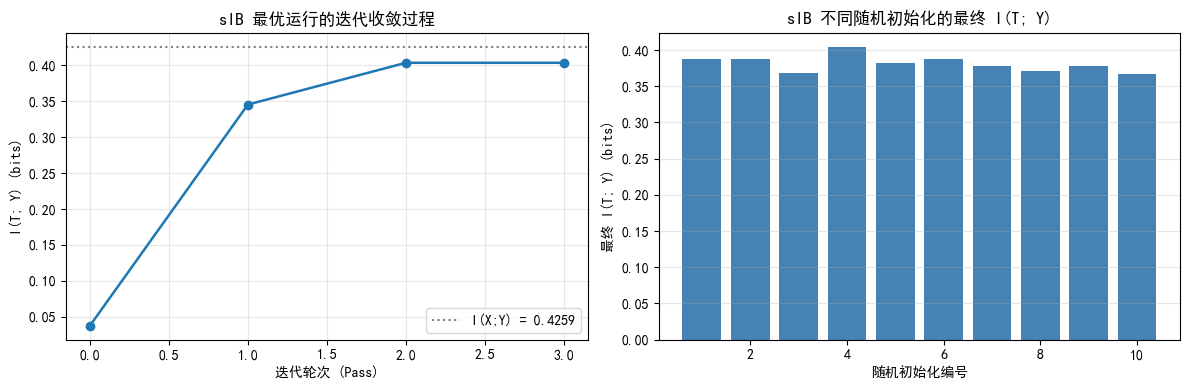

In [11]:
sib_res = sequential_ib(p_x, p_y_given_x, n_clusters=10, max_iter=100, n_init=10, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(len(sib_res['mi_history'])), sib_res['mi_history'], marker='o', linewidth=1.8)
axes[0].axhline(i_xy, color='gray', linestyle=':', label=f'I(X;Y) = {i_xy:.4f}')
axes[0].set_title('sIB 最优运行的迭代收敛过程')
axes[0].set_xlabel('迭代轮次 (Pass)')
axes[0].set_ylabel('I(T; Y) (bits)')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(range(1, len(sib_res['all_init_scores']) + 1), sib_res['all_init_scores'], color='steelblue')
axes[1].set_title('sIB 不同随机初始化的最终 I(T; Y)')
axes[1].set_xlabel('随机初始化编号')
axes[1].set_ylabel('最终 I(T; Y) (bits)')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 4. 结果对比与评估

Method         |   I(T;Y) |    Ratio |     NMI |     ARI |  Purity
------------------------------------------------------------------
Ground Truth   |   0.4035 |   0.9474 |  1.0000 |  1.0000 |  1.0000
aIB (K=10)     |   0.4035 |   0.9474 |  1.0000 |  1.0000 |  1.0000
sIB (K=10)     |   0.4035 |   0.9474 |  1.0000 |  1.0000 |  1.0000


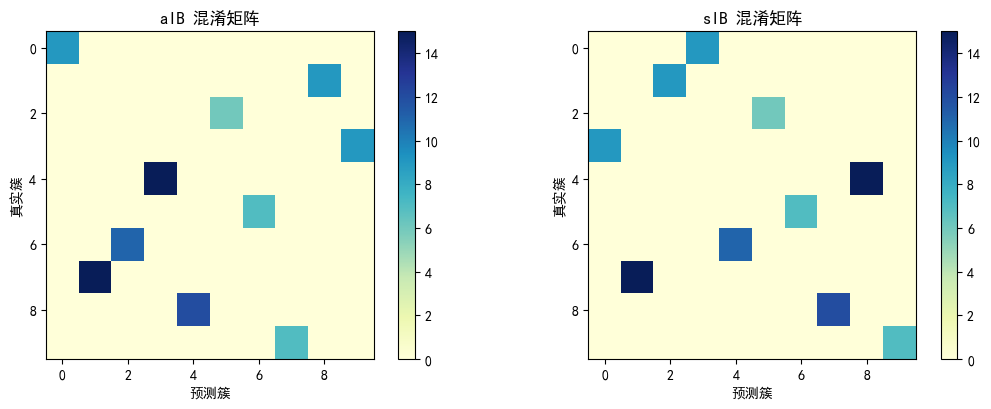

In [12]:
results = {
    'Ground Truth': evaluate_clustering(true_clusters, true_clusters, p_x, p_y_given_x, i_xy),
    'aIB (K=10)': evaluate_clustering(true_clusters, aib_res['labels'], p_x, p_y_given_x, i_xy),
    'sIB (K=10)': evaluate_clustering(true_clusters, sib_res['labels'], p_x, p_y_given_x, i_xy),
}

header = f"{'Method':<14} | {'I(T;Y)':>8} | {'Ratio':>8} | {'NMI':>7} | {'ARI':>7} | {'Purity':>7}"
print(header)
print('-' * len(header))
for name, m in results.items():
    print(f"{name:<14} | {m['I(T;Y)']:>8.4f} | {m['I(T;Y)/I(X;Y)']:>8.4f} | {m['NMI']:>7.4f} | {m['ARI']:>7.4f} | {m['Purity']:>7.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, pred) in zip(axes, [('aIB 混淆矩阵', aib_res['labels']), ('sIB 混淆矩阵', sib_res['labels'])]):
    mat = _contingency_matrix(true_clusters, pred)
    im = ax.imshow(mat, cmap='YlGnBu')
    ax.set_title(title)
    ax.set_xlabel('预测簇')
    ax.set_ylabel('真实簇')
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()